# Experimentos de revisión — CAN IDS CNN–LSTM (OTIDS)

Este cuaderno complementa `modelo_2026_temporal (5).ipynb` y ejecuta los experimentos pedidos en la revisión:

| Bloque | Comentario de la revisión | Qué produce |
| --- | --- | --- |
| R1 | M7 | Diagnóstico del segundo token del campo ID (¿bit RTR / trama remota?) |
| R2 | M1 | Identificación de IDs inyectados y etiqueta por mensaje |
| R3 | M1 | Ventanas con etiqueta por archivo **y** por ventana; tabla de ventanas sin inyección |
| R4 | M2 | Baselines triviales: clase mayoritaria, histograma de IDs, mensaje individual, regla |
| R5 | M4, M5, Tabla 14 | Protocolo aleatorio vs. cronológico con el **mismo** CNN–LSTM V3-C, varias semillas |
| R6 | M6 | Baselines ajustados con la validación cronológica (RF, HistGradientBoosting, LR) |
| R7 | M6, M7 | Ablación y variantes de representación (sin CNN, sin LSTM, sin pooling, +Δt, +RTR, embedding de ID) |
| R8 | M7 | Sensibilidad a la longitud de ventana |
| R9 | M5 | McNemar exacto contra todos los modelos con corrección de Holm + IC bootstrap |
| R10 | M11 | Latencia con lote 1, duración de ventana, tamaño del modelo |
| CH | M1 | Segundo dataset con etiqueta real por trama (Car-Hacking): etiqueta por archivo vs. por ventana |
| R11 | Formato | Figuras estilo IEEE (PDF vectorial, fondo blanco, 8 pt) |

**Cómo ejecutarlo**

1. En Colab: *Entorno de ejecución → Cambiar tipo → GPU T4*. Cada entrenamiento del CNN–LSTM tarda ~13 min en CPU y ~2 min en GPU.
2. Ejecuta las celdas 0.x (copiadas de tu cuaderno: librerías, parser y validación).
3. Primero ejecuta todo con `QUICK = True` (1 semilla, pocas épocas) para comprobar que no hay errores; luego pon `QUICK = False`.
4. Todos los resultados se guardan en `OUT_DIR` como CSV/JSON/PDF.

> Nota: en GPU los resultados pueden diferir ligeramente de la ejecución en CPU aunque se use la misma semilla; por eso se reportan media ± desviación sobre varias semillas.

## 0. Celdas de tu cuaderno original (librerías, parser, validación, partición y ventanas)
Copiadas sin cambios de `modelo_2026_temporal (5).ipynb`. Ejecútalas primero.

## Importación de librerías necesarias para el procesamiento de datos

In [ ]:
# ============================================================
# IMPORTACIÓN DE LIBRERÍAS
# ============================================================

import os
import re
import random
import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.preprocessing import LabelEncoder, MinMaxScaler
from sklearn.model_selection import train_test_split

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    Conv1D,
    MaxPooling1D,
    LSTM,
    Dense,
    Dropout
)



import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score
)
# Importar librerías para visualización de datos y métricas de evaluación
import seaborn as sns                    # Visualizaciones estadísticas elegantes
from time import time

In [ ]:
# ============================================================
# REPRODUCIBILIDAD DEL EXPERIMENTO
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

try:
    tf.config.experimental.enable_op_determinism()
except Exception:
    pass

print("✅ Semilla fijada:", SEED)

✅ Semilla fijada: 42


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Carga de Datasets

In [ ]:
# ============================================================
# PARSER OTIDS V2
# Compatible con registros DLC = 0 sin payload
# ============================================================

import os
import re
import gc
import pandas as pd

folder = "/content/drive/MyDrive/Datasets"

files = [
    "Attack_free_dataset.txt",
    "DoS_attack_dataset.txt",
    "Fuzzy_attack_dataset.txt",
    "Impersonation_attack_dataset.txt"
]

# Verificar archivos
print("Archivos encontrados:")

for file_name in files:
    file_path = os.path.join(folder, file_name)

    if not os.path.isfile(file_path):
        raise FileNotFoundError(
            f"No se encontró: {file_path}"
        )

    print("✅", file_name)


# ============================================================
# REGEX V2
# Payload opcional cuando DLC = 0
# ============================================================

pattern = re.compile(
    r"Timestamp:\s+([\d.]+)\s+"
    r"ID:\s+([0-9A-Fa-f]+\s+[0-9]{3})\s+"
    r"DLC:\s+(\d+)"
    r"(?:\s+(.*))?$"
)


# ============================================================
# EXTRAER REGISTROS
# ============================================================

all_data = []

print("\n================ CARGA DE DATASETS ================")

for file_name in files:

    file_path = os.path.join(folder, file_name)

    count = 0

    print(f"\nLeyendo: {file_name}")

    with open(
        file_path,
        "r",
        encoding="latin-1",
        errors="ignore"
    ) as f:

        for line in f:

            match = pattern.search(line.strip())

            if match:

                timestamp = match.group(1)
                can_id = match.group(2)
                dlc = match.group(3)
                data = match.group(4)

                if data is None:
                    data = ""

                all_data.append({
                    "file": file_name,
                    "timestamp": float(timestamp),
                    "id": can_id,
                    "dlc": int(dlc),
                    "data": data.strip()
                })

                count += 1

    print(f"Registros extraídos: {count:,}")


# ============================================================
# DATAFRAME
# ============================================================

df_all = pd.DataFrame(
    all_data,
    columns=[
        "file",
        "timestamp",
        "id",
        "dlc",
        "data"
    ]
)

del all_data
gc.collect()


print("\n================ RESULTADO PARSER V2 ================")

print("Dimensión df_all:", df_all.shape)

print("\nRegistros por archivo:")
print(df_all["file"].value_counts())

print("\nRegistros DLC = 0:")
print(f"{(df_all['dlc'] == 0).sum():,}")

Archivos encontrados:
✅ Attack_free_dataset.txt
✅ DoS_attack_dataset.txt
✅ Fuzzy_attack_dataset.txt
✅ Impersonation_attack_dataset.txt

================ CARGA DE DATASETS ================

Leyendo: Attack_free_dataset.txt
Registros extraídos: 2,369,398

Leyendo: DoS_attack_dataset.txt
Registros extraídos: 656,579

Leyendo: Fuzzy_attack_dataset.txt
Registros extraídos: 591,990

Leyendo: Impersonation_attack_dataset.txt
Registros extraídos: 995,472

================ RESULTADO PARSER V2 ================
Dimensión df_all: (4613439, 5)

Registros por archivo:
file
Attack_free_dataset.txt             2369398
Impersonation_attack_dataset.txt     995472
DoS_attack_dataset.txt               656579
Fuzzy_attack_dataset.txt             591990
Name: count, dtype: int64

Registros DLC = 0:
123,754


In [ ]:
# ============================================================
# VALIDACIÓN CAN V2
# Compatible con DLC = 0
# ============================================================

import re
import pandas as pd


def is_valid_can_record(row):
    """
    Validación conjunta de DLC y payload.

    Reglas:
    - DLC debe estar entre 0 y 8.
    - DLC = 0 implica payload vacío válido.
    - DLC > 0 requiere exactamente DLC bytes.
    - Cada byte debe ser hexadecimal válido (00-FF).
    """

    # --------------------------------------------------------
    # DLC
    # --------------------------------------------------------
    try:
        dlc = int(row["dlc"])
    except (ValueError, TypeError):
        return False

    if not 0 <= dlc <= 8:
        return False

    # --------------------------------------------------------
    # Payload
    # --------------------------------------------------------
    data = row["data"]

    if pd.isna(data):
        data_str = ""
    else:
        data_str = str(data).strip()

    # --------------------------------------------------------
    # DLC = 0
    # Payload vacío es válido
    # --------------------------------------------------------
    if dlc == 0:
        return data_str == ""

    # --------------------------------------------------------
    # DLC > 0
    # Debe existir payload
    # --------------------------------------------------------
    if data_str == "":
        return False

    parts = data_str.split()

    # Número de bytes debe coincidir con DLC
    if len(parts) != dlc:
        return False

    # --------------------------------------------------------
    # Validación hexadecimal byte a byte
    # --------------------------------------------------------
    for part in parts:

        if re.fullmatch(
            r"[0-9A-Fa-f]{1,2}",
            part
        ) is None:
            return False

        try:
            value = int(part, 16)
        except ValueError:
            return False

        if not 0 <= value <= 255:
            return False

    return True


# ============================================================
# APLICAR VALIDACIÓN
# ============================================================

print(
    "Registros antes de validación:",
    f"{len(df_all):,}"
)

valid_can_mask = df_all.apply(
    is_valid_can_record,
    axis=1
)

invalid_can = (
    df_all.loc[~valid_can_mask]
    .copy()
)

df_clean = (
    df_all.loc[valid_can_mask]
    .copy()
    .reset_index(drop=True)
)


# ============================================================
# RESULTADOS
# ============================================================

print("\n==============================================")
print("VALIDACIÓN CAN V2")
print("==============================================")

print(
    "Registros válidos:",
    f"{len(df_clean):,}"
)

print(
    "Registros inválidos:",
    f"{len(invalid_can):,}"
)

print("\nInválidos por archivo:")

if len(invalid_can) > 0:
    print(
        invalid_can["file"].value_counts()
    )
else:
    print("Ninguno")


print("\nDistribución final:")
print(
    df_clean["file"].value_counts()
)


# ============================================================
# DLC = 0
# ============================================================

print("\n==============================================")
print("COMPROBACIÓN DLC = 0")
print("==============================================")

print(
    "DLC = 0 antes:",
    f"{(df_all['dlc'] == 0).sum():,}"
)

print(
    "DLC = 0 después:",
    f"{(df_clean['dlc'] == 0).sum():,}"
)


# ============================================================
# ASSERTS DE SEGURIDAD
# ============================================================

assert len(df_all) == 4613439
assert len(df_clean) == 4613437
assert len(invalid_can) == 2

assert (
    (df_clean["dlc"] == 0).sum()
    == 123754
)

print(
    "\n✅ df_clean V2 reconstruido correctamente."
)

Registros antes de validación: 4,613,439

VALIDACIÓN CAN V2
Registros válidos: 4,613,437
Registros inválidos: 2

Inválidos por archivo:
file
Fuzzy_attack_dataset.txt    2
Name: count, dtype: int64

Distribución final:
file
Attack_free_dataset.txt             2369398
Impersonation_attack_dataset.txt     995472
DoS_attack_dataset.txt               656579
Fuzzy_attack_dataset.txt             591988
Name: count, dtype: int64

COMPROBACIÓN DLC = 0
DLC = 0 antes: 123,754
DLC = 0 después: 123,754

✅ df_clean V2 reconstruido correctamente.


In [ ]:
# ============================================================
# TEMPORAL SPLIT BY OTIDS SOURCE FILE
# 64% TRAIN / 16% VALIDATION / 20% TEMPORAL TEST
# ============================================================

import numpy as np
import pandas as pd

TRAIN_RATIO = 0.64
VAL_RATIO   = 0.16
TEST_RATIO  = 0.20

temporal_train_parts = []
temporal_val_parts = []
temporal_test_parts = []


print("=" * 75)
print("TEMPORAL SPLIT BY SOURCE FILE")
print("=" * 75)


for file_name in df_clean["file"].unique():

    df_file = (
        df_clean.loc[
            df_clean["file"] == file_name
        ]
        .sort_values(
            by="timestamp",
            kind="mergesort"
        )
        .reset_index(drop=True)
    )

    n = len(df_file)

    train_end = int(
        np.floor(n * TRAIN_RATIO)
    )

    val_end = int(
        np.floor(
            n * (TRAIN_RATIO + VAL_RATIO)
        )
    )

    df_train_file = (
        df_file.iloc[:train_end]
        .copy()
    )

    df_val_file = (
        df_file.iloc[
            train_end:val_end
        ]
        .copy()
    )

    df_test_file = (
        df_file.iloc[
            val_end:
        ]
        .copy()
    )


    temporal_train_parts.append(
        df_train_file
    )

    temporal_val_parts.append(
        df_val_file
    )

    temporal_test_parts.append(
        df_test_file
    )


    print(
        f"\n{file_name}"
    )

    print(
        f"Total:      {n:,}"
    )

    print(
        f"Train:      {len(df_train_file):,}"
    )

    print(
        f"Validation: {len(df_val_file):,}"
    )

    print(
        f"Test:       {len(df_test_file):,}"
    )

    print(
        f"Train time: "
        f"{df_train_file['timestamp'].min():.6f}"
        f" → "
        f"{df_train_file['timestamp'].max():.6f}"
    )

    print(
        f"Val time:   "
        f"{df_val_file['timestamp'].min():.6f}"
        f" → "
        f"{df_val_file['timestamp'].max():.6f}"
    )

    print(
        f"Test time:  "
        f"{df_test_file['timestamp'].min():.6f}"
        f" → "
        f"{df_test_file['timestamp'].max():.6f}"
    )


df_temporal_train = (
    pd.concat(
        temporal_train_parts,
        ignore_index=True
    )
)

df_temporal_val = (
    pd.concat(
        temporal_val_parts,
        ignore_index=True
    )
)

df_temporal_test = (
    pd.concat(
        temporal_test_parts,
        ignore_index=True
    )
)


print("\n" + "=" * 75)
print("GLOBAL TEMPORAL SPLIT")
print("=" * 75)

print(
    "Train messages:",
    f"{len(df_temporal_train):,}"
)

print(
    "Validation messages:",
    f"{len(df_temporal_val):,}"
)

print(
    "Temporal Test messages:",
    f"{len(df_temporal_test):,}"
)

print(
    "Total:",
    f"{len(df_temporal_train) + len(df_temporal_val) + len(df_temporal_test):,}"
)


assert (
    len(df_temporal_train)
    + len(df_temporal_val)
    + len(df_temporal_test)
    == len(df_clean)
)

print(
    "\n✅ Temporal split completed without message loss."
)

TEMPORAL SPLIT BY SOURCE FILE

Attack_free_dataset.txt
Total:      2,369,398
Train:      1,516,414
Validation: 379,104
Test:       473,880
Train time: 0.000000 → 664.051065
Val time:   664.051299 → 830.066854
Test time:  830.067624 → 1037.590316

DoS_attack_dataset.txt
Total:      656,579
Train:      420,210
Validation: 105,053
Test:       131,316
Train time: 0.000000 → 211.507716
Val time:   211.507964 → 246.215613
Test time:  246.215856 → 306.296857

Fuzzy_attack_dataset.txt
Total:      591,988
Train:      378,872
Validation: 94,718
Test:       118,398
Train time: 0.000000 → 220.693332
Val time:   220.694362 → 262.353942
Test time:  262.354902 → 347.331739

Impersonation_attack_dataset.txt
Total:      995,472
Train:      637,102
Validation: 159,275
Test:       199,095
Train time: 1481192898.075465 → 1481193209.021469
Val time:   1481193209.022040 → 1481193286.096923
Test time:  1481193286.097159 → 1481193380.725113

GLOBAL TEMPORAL SPLIT
Train messages: 2,952,598
Validation messages:

In [ ]:
# ============================================================
# TEMPORAL WINDOW CONSTRUCTION
# 20 messages x 10 features
#
# FEATURES:
# CAN ID + DLC + DATA0...DATA7
#
# IMPORTANT:
# Windows are constructed independently inside
# Train / Validation / Temporal Test.
# ============================================================

import numpy as np


WINDOW_SIZE = 20

FILE_ORDER = [
    "Attack_free_dataset.txt",
    "DoS_attack_dataset.txt",
    "Fuzzy_attack_dataset.txt",
    "Impersonation_attack_dataset.txt"
]

LABEL_MAP = {
    "Attack_free_dataset.txt": 0,
    "DoS_attack_dataset.txt": 1,
    "Fuzzy_attack_dataset.txt": 2,
    "Impersonation_attack_dataset.txt": 3
}


# ============================================================
# AUXILIARY FUNCTIONS
# ============================================================

def convert_can_id_temporal(value):
    """
    Converts the first hexadecimal CAN-ID token
    into its decimal representation.
    """
    first_token = str(value).strip().split()[0]
    return int(first_token, 16)


def expand_payload_temporal(data_str):
    """
    Converts payload to 8 decimal bytes.
    DLC=0 / empty payload -> eight zeros.
    """

    data_str = str(data_str).strip()

    values = np.zeros(
        8,
        dtype=np.float32
    )

    if data_str != "":
        parts = data_str.split()

        for i, part in enumerate(parts[:8]):
            values[i] = int(part, 16)

    return values


# ============================================================
# BUILD WINDOWS FOR ONE TEMPORAL PARTITION
# ============================================================

def build_temporal_windows(
    df_partition,
    partition_name
):

    X_parts = []
    y_parts = []
    ts_parts = []

    total_remainder = 0

    print("\n" + "=" * 75)
    print(partition_name)
    print("=" * 75)

    for file_name in FILE_ORDER:

        df_file = (
            df_partition.loc[
                df_partition["file"] == file_name
            ]
            .sort_values(
                "timestamp",
                kind="mergesort"
            )
            .reset_index(drop=True)
        )

        n_messages = len(df_file)

        n_windows = (
            n_messages // WINDOW_SIZE
        )

        n_used = (
            n_windows * WINDOW_SIZE
        )

        remainder = (
            n_messages - n_used
        )

        total_remainder += remainder


        # ----------------------------------------------------
        # CAN ID
        # ----------------------------------------------------

        can_id_array = (
            df_file["id"]
            .apply(convert_can_id_temporal)
            .to_numpy(
                dtype=np.float32
            )
        )


        # ----------------------------------------------------
        # DLC
        # ----------------------------------------------------

        dlc_array = (
            df_file["dlc"]
            .to_numpy(
                dtype=np.float32
            )
        )


        # ----------------------------------------------------
        # PAYLOAD DATA0...DATA7
        # ----------------------------------------------------

        payload_array = np.stack(
            df_file["data"]
            .apply(expand_payload_temporal)
            .to_numpy()
        ).astype(np.float32)


        # ----------------------------------------------------
        # 10 FEATURES
        # ----------------------------------------------------

        features_file = np.column_stack([
            can_id_array,
            dlc_array,
            payload_array
        ]).astype(np.float32)


        # Keep only complete windows
        features_file = (
            features_file[:n_used]
        )

        timestamps_file = (
            df_file["timestamp"]
            .to_numpy()[:n_used]
        )


        # ----------------------------------------------------
        # RESHAPE
        # ----------------------------------------------------

        X_file = features_file.reshape(
            n_windows,
            WINDOW_SIZE,
            10
        )

        y_file = np.full(
            n_windows,
            LABEL_MAP[file_name],
            dtype=np.int32
        )

        # timestamp of first message of each window
        ts_file = timestamps_file[
            ::WINDOW_SIZE
        ]


        X_parts.append(X_file)
        y_parts.append(y_file)
        ts_parts.append(ts_file)


        print(
            f"{file_name}: "
            f"{n_messages:,} messages -> "
            f"{n_windows:,} windows | "
            f"remainder = {remainder}"
        )


    X_partition = np.concatenate(
        X_parts,
        axis=0
    )

    y_partition = np.concatenate(
        y_parts,
        axis=0
    )

    ts_partition = np.concatenate(
        ts_parts,
        axis=0
    )


    print("\n----------------------------------------------")

    print(
        "X:",
        X_partition.shape
    )

    print(
        "y:",
        y_partition.shape
    )

    print(
        "ts:",
        ts_partition.shape
    )

    print(
        "Residual messages:",
        total_remainder
    )


    assert X_partition.shape[1:] == (
        20,
        10
    )

    assert len(X_partition) == len(y_partition)

    assert len(X_partition) == len(ts_partition)


    return (
        X_partition,
        y_partition,
        ts_partition
    )

In [ ]:
# ============================================================
# BUILD ALL TEMPORAL WINDOWS
# ============================================================

X_temporal_train_raw, y_temporal_train, ts_temporal_train = (
    build_temporal_windows(
        df_temporal_train,
        "TEMPORAL TRAIN"
    )
)

X_temporal_val_raw, y_temporal_val, ts_temporal_val = (
    build_temporal_windows(
        df_temporal_val,
        "TEMPORAL VALIDATION"
    )
)

X_temporal_test_raw, y_temporal_test, ts_temporal_test = (
    build_temporal_windows(
        df_temporal_test,
        "TEMPORAL TEST"
    )
)


TEMPORAL TRAIN
Attack_free_dataset.txt: 1,516,414 messages -> 75,820 windows | remainder = 14
DoS_attack_dataset.txt: 420,210 messages -> 21,010 windows | remainder = 10
Fuzzy_attack_dataset.txt: 378,872 messages -> 18,943 windows | remainder = 12
Impersonation_attack_dataset.txt: 637,102 messages -> 31,855 windows | remainder = 2

----------------------------------------------
X: (147628, 20, 10)
y: (147628,)
ts: (147628,)
Residual messages: 38

TEMPORAL VALIDATION
Attack_free_dataset.txt: 379,104 messages -> 18,955 windows | remainder = 4
DoS_attack_dataset.txt: 105,053 messages -> 5,252 windows | remainder = 13
Fuzzy_attack_dataset.txt: 94,718 messages -> 4,735 windows | remainder = 18
Impersonation_attack_dataset.txt: 159,275 messages -> 7,963 windows | remainder = 15

----------------------------------------------
X: (36905, 20, 10)
y: (36905,)
ts: (36905,)
Residual messages: 50

TEMPORAL TEST
Attack_free_dataset.txt: 473,880 messages -> 23,694 windows | remainder = 0
DoS_attack_

## R0. Configuración de la revisión

In [ ]:
# ============================================================
# R0. CONFIGURACIÓN
# ============================================================
import os, json, time, gc, warnings
import numpy as np
import pandas as pd
from scipy.stats import binomtest
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split, PredefinedSplit, GridSearchCV
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, matthews_corrcoef, confusion_matrix)
warnings.filterwarnings("ignore", category=FutureWarning)

QUICK = False                    # True = prueba rápida; False = experimento completo
SEEDS = [42] if QUICK else [42, 7, 123, 2024, 31415]
EPOCHS_MAX = 3 if QUICK else 30
BATCH_SIZE = 64
WINDOW_SIZE = 20

OUT_DIR = "/content/drive/MyDrive/CAN_IDS_FINAL_EVIDENCE/REVISION"
os.makedirs(OUT_DIR, exist_ok=True)

FILE_ORDER = ["Attack_free_dataset.txt", "DoS_attack_dataset.txt",
              "Fuzzy_attack_dataset.txt", "Impersonation_attack_dataset.txt"]
LABEL_MAP = {f: i for i, f in enumerate(FILE_ORDER)}
CLASS_NAMES = ["Attack-free", "DoS", "Fuzzy", "Impersonation"]

import pickle
RES_CSV = os.path.join(OUT_DIR, "revision_results.csv")
PRED_PKL = os.path.join(OUT_DIR, "revision_predictions.pkl")
RESULTS = []          # una fila por (experimento, modelo, semilla)
PREDICTIONS = {}      # predicciones de prueba para McNemar

# ---- REANUDAR: si la sesión se cortó, se cargan los resultados ya guardados en Drive ----
RESUME = True
if RESUME and os.path.isfile(RES_CSV):
    RESULTS = pd.read_csv(RES_CSV).to_dict("records")
    print(f"Reanudando: {len(RESULTS)} resultados previos cargados de {RES_CSV}")
if RESUME and os.path.isfile(PRED_PKL):
    with open(PRED_PKL, "rb") as fh:
        PREDICTIONS = pickle.load(fh)
    print(f"Reanudando: {len(PREDICTIONS)} vectores de predicción cargados")

def save_results(name="revision_results.csv"):
    pd.DataFrame(RESULTS).to_csv(os.path.join(OUT_DIR, name), index=False)
    with open(PRED_PKL, "wb") as fh:
        pickle.dump(PREDICTIONS, fh)

def _has_row(exp, model, seed):
    return any(r["experiment"] == exp and r["model"] == model and int(r["seed"]) == int(seed) for r in RESULTS)

def need(exp, model, seed):
    # True = hay que entrenar. Se salta si ya hay resultado; la semilla 42 además necesita
    # sus predicciones guardadas (las usan McNemar y las figuras).
    if not _has_row(exp, model, seed):
        return True
    return int(seed) == 42 and (exp, model, seed) not in PREDICTIONS

print("QUICK =", QUICK, "| SEEDS =", SEEDS, "| OUT_DIR =", OUT_DIR)

Reanudando: 128 resultados previos cargados de /content/drive/MyDrive/CAN_IDS_FINAL_EVIDENCE/REVISION/revision_results.csv
Reanudando: 118 vectores de predicción cargados
QUICK = False | SEEDS = [42, 7, 123, 2024, 31415] | OUT_DIR = /content/drive/MyDrive/CAN_IDS_FINAL_EVIDENCE/REVISION


## R1. Diagnóstico del campo ID (comentario M7)

El parser guarda `id` como `"<hex> <3 dígitos>"` (p. ej. `"0316 000"`) y el modelo solo usa el primer token. Esta celda muestra qué contiene el segundo token y si coincide con los 123,754 registros con DLC = 0. Si el segundo token distingue tramas remotas, debe describirse en el artículo y probarse como rasgo (`rtr`).

In [ ]:
# ============================================================
# R1. ENRIQUECER df_clean: can_id, id_flag, rtr, d0..d7
# ============================================================
tok = df_clean["id"].astype(str).str.split()
df_clean["can_id"] = tok.str[0].map(lambda s: int(s, 16)).astype(np.int64)
df_clean["id_flag"] = tok.str[1].fillna("NA")

print("Segundo token del campo ID por archivo:")
print(pd.crosstab(df_clean["file"], df_clean["id_flag"]))
print("\nSegundo token vs. DLC = 0:")
print(pd.crosstab(df_clean["id_flag"], df_clean["dlc"] == 0,
                  rownames=["id_flag"], colnames=["DLC == 0"]))

# VERIFICAR antes de usar: se asume que un id_flag distinto del más frecuente
# marca una trama remota (RTR). Ajusta esta línea según lo que muestren las tablas.
MAIN_FLAG = df_clean["id_flag"].mode()[0]
df_clean["rtr"] = (df_clean["id_flag"] != MAIN_FLAG).astype(np.float32)
print(f"\nFlag mayoritario: {MAIN_FLAG!r} | registros con rtr = 1: {int(df_clean['rtr'].sum()):,}")

# Payload vectorizado (equivalente a expand_payload_temporal)
P = (df_clean["data"].astype(str).str.split(expand=True)
     .reindex(columns=range(8)))
for k in range(8):
    df_clean[f"d{k}"] = (P[k].fillna("0").replace("", "0")
                         .map(lambda s: int(s, 16)).astype(np.float32))
del P, tok; gc.collect()
print("✅ Columnas añadidas: can_id, id_flag, rtr, d0..d7")

Segundo token del campo ID por archivo:
id_flag                               000     100
file                                             
Attack_free_dataset.txt           2268519  100879
DoS_attack_dataset.txt             645785   10794
Fuzzy_attack_dataset.txt           579907   12081
Impersonation_attack_dataset.txt   990752    4720

Segundo token vs. DLC = 0:
DLC == 0    False   True 
id_flag                  
000       4484963       0
100          4720  123754

Flag mayoritario: '000' | registros con rtr = 1: 128,474
✅ Columnas añadidas: can_id, id_flag, rtr, d0..d7


## R2. IDs inyectados y etiqueta por mensaje (comentario M1)

La etiqueta actual es el **archivo** de origen. Los archivos de ataque contienen mayoritariamente tráfico normal, así que muchas ventanas etiquetadas como "DoS", "Fuzzy" o "Impersonation" no contienen ningún mensaje inyectado.

**Lo que se sabe de OTIDS** (Verma et al., *PLOS ONE* 2024, análisis del dataset):

- Los mensajes inyectados **no vienen etiquetados**; las tramas remotas sí están marcadas.
- DoS: todos los mensajes con ID 0x000 son inyecciones → se puede etiquetar con seguridad.
- Fuzzy: solo suplanta **IDs que existen en el tráfico normal** → el ID no basta para etiquetarlo.
- Impersonation: el ejemplo documentado es el ID 0x164, con respuestas maliciosas a tramas remotas (p. ej. carga `01 02 03 04 05 06 07 08`) → puede etiquetarse si la carga maliciosa es reconocible.

Las celdas siguientes lo comprueban en tus datos. Lo que no se pueda etiquetar con seguridad conserva la etiqueta por archivo y se declara como limitación; para una evaluación con etiqueta real por mensaje se usa además el dataset Car-Hacking (bloque CH).

In [ ]:
# ============================================================
# R2a. DIAGNÓSTICO DE IDs POR ARCHIVO
# ============================================================
def duration(d):
    return float(d["timestamp"].max() - d["timestamp"].min())

af = df_clean[df_clean["file"] == FILE_ORDER[0]]
normal_ids = set(af["can_id"].unique())
rate_af = af["can_id"].value_counts() / duration(af)
print(f"IDs en Attack-free: {len(normal_ids)}")

ID_DIAG = {}
for f in FILE_ORDER[1:]:
    d = df_clean[df_clean["file"] == f]
    rate = d["can_id"].value_counts() / duration(d)
    comp = pd.DataFrame({"rate_attack": rate, "rate_normal": rate_af}).fillna(0.0)
    comp["ratio"] = (comp["rate_attack"] + 1e-9) / (comp["rate_normal"] + 1e-9)
    new_ids = comp.index[comp["rate_normal"] == 0]
    n_new = int(d["can_id"].isin(new_ids).sum())
    ID_DIAG[f] = comp.sort_values("ratio", ascending=False)
    print("\n" + "=" * 70)
    print(f"{f}: {len(d):,} mensajes | IDs ausentes en Attack-free: {len(new_ids)} "
          f"({n_new:,} mensajes, {100*n_new/len(d):.2f}%)")
    print(ID_DIAG[f].head(8).to_string(float_format=lambda x: f"{x:,.3f}"))

IDs en Attack-free: 45

DoS_attack_dataset.txt: 656,579 mensajes | IDs ausentes en Attack-free: 1 (335,624 mensajes, 51.12%)
        rate_attack  rate_normal                 ratio
can_id                                                
0         1,095.747        0.000 1,095,747,449,998.503
24            2.677        5.003                 0.535
52            0.532        1.000                 0.532
66            0.532        1.000                 0.532
1296          5.175       10.000                 0.517
399          51.744      100.000                 0.517
67            0.516        1.000                 0.516
357          51.558       99.998                 0.516

Fuzzy_attack_dataset.txt: 591,988 mensajes | IDs ausentes en Attack-free: 0 (0 mensajes, 0.00%)
        rate_attack  rate_normal  ratio
can_id                                 
1440         86.059       22.604  3.807
1442         84.553       22.602  3.741
704          91.109       31.604  2.883
24            8.784        5

In [ ]:
# ============================================================
# R2a2. DIAGNÓSTICO DE IMPERSONATION (ID 0x164) Y TRAMAS REMOTAS
# ============================================================
CAND_IMP = 0x164
df_clean["data_norm"] = df_clean["data"].astype(str).str.upper().str.split().str.join(" ")
for f in FILE_ORDER:
    d = df_clean[df_clean["file"] == f]
    di = d[d["can_id"] == CAND_IMP]
    print("\n" + "=" * 70)
    print(f"{f}: {len(di):,} mensajes con ID 0x{CAND_IMP:03X} "
          f"({len(di) / duration(d):.2f} msg/s) | tramas con rtr=1: {int(d['rtr'].sum()):,}")
    print("Cargas útiles más frecuentes de 0x164:")
    print(di["data_norm"].value_counts().head(6).to_string())

# Cargas de 0x164 que aparecen en Impersonation pero NUNCA en Attack-free
pay_af = set(df_clean.loc[(df_clean["file"] == FILE_ORDER[0]) & (df_clean["can_id"] == CAND_IMP), "data_norm"])
imp164 = df_clean[(df_clean["file"] == FILE_ORDER[3]) & (df_clean["can_id"] == CAND_IMP)]
novel = imp164.loc[~imp164["data_norm"].isin(pay_af), "data_norm"].value_counts()
print(f"\nCargas de 0x164 exclusivas de Impersonation: {len(novel)} distintas, {int(novel.sum()):,} mensajes")
print(novel.head(6).to_string())


Attack_free_dataset.txt: 126,605 mensajes con ID 0x164 (122.02 msg/s) | tramas con rtr=1: 100,879
Cargas útiles más frecuentes de 0x164:
data_norm
                           11209
00 08 00 00 00 00 03 0B     7247
00 08 00 00 00 00 0F 07     7236
00 08 00 00 00 00 07 0F     7235
00 08 00 00 00 00 0B 03     7230
00 08 00 00 00 00 04 0C     7226

DoS_attack_dataset.txt: 17,271 mensajes con ID 0x164 (56.39 msg/s) | tramas con rtr=1: 10,794
Cargas útiles más frecuentes de 0x164:
data_norm
                           1231
00 08 00 00 00 00 08 00    1056
00 08 00 00 00 00 04 0C    1041
00 08 00 00 00 00 03 0B    1026
00 08 00 00 00 00 0A 02    1017
00 08 00 00 00 00 0C 04    1015

Fuzzy_attack_dataset.txt: 41,590 mensajes con ID 0x164 (119.74 msg/s) | tramas con rtr=1: 12,081
Cargas útiles más frecuentes de 0x164:
data_norm
                           1376
00 08 01 00 00 00 0F 06     889
00 08 01 00 00 00 09 00     873
00 08 01 00 00 00 08 01     861
00 08 01 00 00 00 07 0E     859
00 08 01 00

In [ ]:
# ============================================================
# R2b. FIJAR IDs INYECTADOS  (REVISAR Y CONFIRMAR CON [13])
# ============================================================
# DoS: sugerencia automática = ID con mayor razón de tasa en el archivo DoS.
DOS_ID = int(ID_DIAG[FILE_ORDER[1]].index[0])
print(f"DoS: ID sugerido = 0x{DOS_ID:03X}  -> confirmar")

# Fuzzy: en OTIDS solo se suplantan IDs legítimos (Verma et al., 2024). Si R2a muestra
# 0 IDs ausentes del Attack-free, Fuzzy NO se puede etiquetar por mensaje y conserva la
# etiqueta por archivo. Si aparecen IDs nuevos, se marcan como inyectados (cota inferior).
fuzzy_unknown = int((~df_clean.loc[df_clean["file"] == FILE_ORDER[2], "can_id"].isin(normal_ids)).sum())
FUZZY_LABELABLE = fuzzy_unknown > 0
print(f"Fuzzy: {fuzzy_unknown:,} mensajes con ID desconocido -> etiquetable: {FUZZY_LABELABLE}")

# Impersonation: elige UNA de las dos opciones según R2a2 y R2c.
#   a) Carga maliciosa reconocible: IMP_ID = 0x164 y IMP_PAYLOADS = cargas exclusivas de R2a2
#   b) Inicio del ataque conocido:  IMP_ID = 0x164 y IMP_START = timestamp absoluto
# Si ninguna se puede justificar, deja todo en None: Impersonation conserva la etiqueta por archivo.
IMP_ID = 0x164                              # confirmado en R2a2 (3/11/2026)
IMP_PAYLOADS = ["01 02 03 04 05 06 07 08"]  # 5,697 mensajes, exclusivos de Impersonation
IMP_START = None           # p. ej. 1481192898.0  (VERIFICAR con R2c)
IMP_LABELABLE = IMP_ID is not None and (IMP_PAYLOADS is not None or IMP_START is not None)

# Archivos cuya etiqueta por ventana NO se puede reconstruir: conservan la etiqueta por archivo
KEEP_FILE_LABEL = set()
if not FUZZY_LABELABLE: KEEP_FILE_LABEL.add(FILE_ORDER[2])
if not IMP_LABELABLE:   KEEP_FILE_LABEL.add(FILE_ORDER[3])
print("Conservan etiqueta por archivo:", sorted(KEEP_FILE_LABEL) or "ninguno")

def label_injected(d):
    f = d["file"].to_numpy()
    cid = d["can_id"].to_numpy()
    ts = d["timestamp"].to_numpy()
    inj = (f == FILE_ORDER[1]) & (cid == DOS_ID)
    if FUZZY_LABELABLE:
        inj |= (f == FILE_ORDER[2]) & ~np.isin(cid, list(normal_ids))
    if IMP_LABELABLE:
        m = (f == FILE_ORDER[3]) & (cid == IMP_ID)
        if IMP_PAYLOADS is not None:
            m &= d["data_norm"].isin([x.upper() for x in IMP_PAYLOADS]).to_numpy()
        if IMP_START is not None:
            m &= ts >= IMP_START
        inj |= m
    return inj

df_clean["injected"] = label_injected(df_clean)
summary_inj = (df_clean.groupby("file")["injected"]
               .agg(messages="size", injected="sum").reindex(FILE_ORDER))
summary_inj["injected_%"] = 100 * summary_inj["injected"] / summary_inj["messages"]
print(summary_inj.to_string())
summary_inj.to_csv(os.path.join(OUT_DIR, "R2_injected_messages_per_file.csv"))

DoS: ID sugerido = 0x000  -> confirmar
Fuzzy: 0 mensajes con ID desconocido -> etiquetable: False
Conservan etiqueta por archivo: ['Fuzzy_attack_dataset.txt']
                                  messages  injected  injected_%
file                                                            
Attack_free_dataset.txt            2369398         0    0.000000
DoS_attack_dataset.txt              656579    335624   51.117078
Fuzzy_attack_dataset.txt            591988         0    0.000000
Impersonation_attack_dataset.txt    995472      5697    0.572291


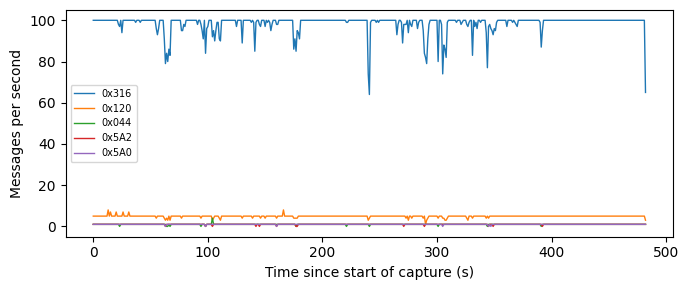

Inicio absoluto del archivo: 1481192898.075465


In [ ]:
# ============================================================
# R2c. AYUDA PARA UBICAR EL INICIO DEL ATAQUE DE IMPERSONATION
# Mensajes por segundo de los IDs con mayor cambio de tasa
# ============================================================
import matplotlib.pyplot as plt
d_imp = df_clean[df_clean["file"] == FILE_ORDER[3]]
t_rel = d_imp["timestamp"] - d_imp["timestamp"].min()
cands = list(ID_DIAG[FILE_ORDER[3]].index[:3]) + list(
    ID_DIAG[FILE_ORDER[3]].sort_values("ratio").index[:2])
fig, ax = plt.subplots(figsize=(7, 3))
for cid in cands:
    m = d_imp["can_id"].to_numpy() == cid
    counts = np.bincount(t_rel.to_numpy()[m].astype(int))
    ax.plot(counts, label=f"0x{cid:03X}", lw=1)
ax.set_xlabel("Time since start of capture (s)")
ax.set_ylabel("Messages per second")
ax.legend(fontsize=7); fig.tight_layout(); plt.show()
print("Inicio absoluto del archivo:", d_imp["timestamp"].min())

## R3. Particiones y ventanas con dos etiquetas (comentario M1)

Se repite exactamente tu partición cronológica 64/16/20 por archivo (mismo `floor`). Cada ventana guarda:

- `y_file`: etiqueta actual (archivo de origen).
- `y_win`: etiqueta corregida = clase del ataque **solo si** la ventana contiene ≥ 1 mensaje inyectado; si no, Attack-free (0).
- `ids` (IDs sin escalar), `dt` (tiempo entre llegadas dentro de la ventana), `rtr`, `inj_frac`.

In [ ]:
# ============================================================
# R3a. PARTICIÓN CRONOLÓGICA Y CONSTRUCCIÓN DE VENTANAS
# ============================================================
NUM_FEATS = ["can_id", "dlc"] + [f"d{k}" for k in range(8)]   # los 10 rasgos originales

def chrono_split(df, tr=0.64, va=0.16):
    parts = {"train": [], "val": [], "test": []}
    for f in FILE_ORDER:
        d = df[df["file"] == f].sort_values("timestamp", kind="mergesort").reset_index(drop=True)
        n = len(d)
        a, b = int(np.floor(n * tr)), int(np.floor(n * (tr + va)))
        parts["train"].append(d.iloc[:a]); parts["val"].append(d.iloc[a:b]); parts["test"].append(d.iloc[b:])
    return {k: pd.concat(v, ignore_index=True) for k, v in parts.items()}

def build_windows(df_part, L=WINDOW_SIZE):
    out = {k: [] for k in ["X", "ids", "dt", "rtr", "y_file", "y_win", "inj_frac", "t0", "t_end"]}
    for f in FILE_ORDER:
        d = df_part[df_part["file"] == f].sort_values("timestamp", kind="mergesort")
        n = len(d) // L * L
        if n == 0:
            continue
        out["X"].append(d[NUM_FEATS].to_numpy(np.float32)[:n].reshape(-1, L, len(NUM_FEATS)))
        out["ids"].append(d["can_id"].to_numpy()[:n].reshape(-1, L))
        ts = d["timestamp"].to_numpy(np.float64)[:n].reshape(-1, L)
        out["dt"].append(np.diff(ts, axis=1, prepend=ts[:, :1]).astype(np.float32))
        out["rtr"].append(d["rtr"].to_numpy(np.float32)[:n].reshape(-1, L))
        inj = d["injected"].to_numpy()[:n].reshape(-1, L)
        yf = np.full(len(inj), LABEL_MAP[f], np.int32)
        yw = yf.copy() if f in KEEP_FILE_LABEL else np.where(inj.any(axis=1), yf, 0).astype(np.int32)
        out["y_file"].append(yf); out["y_win"].append(yw)
        out["inj_frac"].append(inj.mean(axis=1)); out["t0"].append(ts[:, 0]); out["t_end"].append(ts[:, -1])
    return {k: np.concatenate(v) for k, v in out.items()}

SPLIT = chrono_split(df_clean)
W = {k: build_windows(v) for k, v in SPLIT.items()}
for k in W:
    print(f"{k:5s}: {W[k]['X'].shape} | y_file={np.bincount(W[k]['y_file'], minlength=4)} "
          f"| y_win={np.bincount(W[k]['y_win'], minlength=4)}")

# Comprobación: los rasgos coinciden con tu cuaderno original
if "X_temporal_train_raw" in globals():
    assert np.array_equal(W["train"]["X"], X_temporal_train_raw), "Las ventanas no coinciden con el original"
    assert np.array_equal(W["test"]["y_file"], y_temporal_test)
    print("✅ Ventanas idénticas a X_temporal_*_raw del cuaderno original")

train: (147628, 20, 10) | y_file=[75820 21010 18943 31855] | y_win=[104391  21010  18943   3284]
val  : (36905, 20, 10) | y_file=[18955  5252  4735  7963] | y_win=[26097  5252  4735   821]
test : (46132, 20, 10) | y_file=[23694  6565  5919  9954] | y_win=[32643  6565  5919  1005]
✅ Ventanas idénticas a X_temporal_*_raw del cuaderno original


In [ ]:
# ============================================================
# R3b. TABLA NUEVA PARA EL ARTÍCULO:
# ventanas de archivos de ataque SIN ningún mensaje inyectado
# ============================================================
rows = []
for part in ["train", "val", "test"]:
    w = W[part]
    for c in range(1, 4):
        m = w["y_file"] == c
        rows.append({"Partition": part, "Scenario": CLASS_NAMES[c], "Windows": int(m.sum()),
                     "Windows with >=1 injected msg": int((w["inj_frac"][m] > 0).sum()),
                     "Windows without injected msg (%)": 100 * float((w["inj_frac"][m] == 0).mean())})
tab_noinj = pd.DataFrame(rows)
print(tab_noinj.to_string(index=False, float_format=lambda x: f"{x:.2f}"))
tab_noinj.to_csv(os.path.join(OUT_DIR, "R3_windows_without_injection.csv"), index=False)

Partition      Scenario  Windows  Windows with >=1 injected msg  Windows without injected msg (%)
    train           DoS    21010                          21010                              0.00
    train         Fuzzy    18943                              0                            100.00
    train Impersonation    31855                           3284                             89.69
      val           DoS     5252                           5252                              0.00
      val         Fuzzy     4735                              0                            100.00
      val Impersonation     7963                            821                             89.69
     test           DoS     6565                           6565                              0.00
     test         Fuzzy     5919                              0                            100.00
     test Impersonation     9954                           1005                             89.90


## Funciones comunes: preparación, modelos, métricas y estadística

In [ ]:
# ============================================================
# FUNCIONES COMUNES (sin TensorFlow)
# ============================================================
def prepare(Wtr, Wva, Wte, use_dt=False, use_rtr=False):
    # Escala con MinMaxScaler ajustado SOLO con entrenamiento
    def stack(w):
        parts = [w["X"]]
        if use_rtr: parts.append(w["rtr"][..., None])
        if use_dt:  parts.append(np.log1p(w["dt"] * 1e3)[..., None])
        return np.concatenate(parts, axis=2)
    A, B, C = stack(Wtr), stack(Wva), stack(Wte)
    sc = MinMaxScaler().fit(A.reshape(-1, A.shape[2]))
    tf_ = lambda Z: sc.transform(Z.reshape(-1, Z.shape[2])).reshape(Z.shape).astype(np.float32)
    return tf_(A), tf_(B), tf_(C), sc

def get_metrics(y, p):
    return {"accuracy": accuracy_score(y, p),
            "macro_precision": precision_score(y, p, average="macro", zero_division=0),
            "macro_recall": recall_score(y, p, average="macro", zero_division=0),
            "macro_f1": f1_score(y, p, average="macro", zero_division=0),
            "weighted_f1": f1_score(y, p, average="weighted", zero_division=0),
            "mcc": matthews_corrcoef(y, p),
            "errors": int(np.sum(y != p))}

def fpr_fnr(y, p, K=None):
    K = K or int(max(np.max(y), np.max(p)) + 1)
    cm = confusion_matrix(y, p, labels=range(K))
    tp = np.diag(cm); fp = cm.sum(0) - tp; fn = cm.sum(1) - tp; tn = cm.sum() - tp - fp - fn
    with np.errstate(divide="ignore", invalid="ignore"):
        fpr = np.nanmean(fp / (fp + tn)); fnr = np.nanmean(fn / (fn + tp))
    return float(fpr), float(fnr)

def record(exp, model, seed, y, p, **extra):
    global RESULTS
    RESULTS = [r for r in RESULTS if not (r["experiment"] == exp and r["model"] == model
                                          and int(r["seed"]) == int(seed))]
    row = {"experiment": exp, "model": model, "seed": seed, **get_metrics(y, p)}
    row["fpr_macro"], row["fnr_macro"] = fpr_fnr(y, p)
    row.update(extra); RESULTS.append(row)
    PREDICTIONS[(exp, model, seed)] = np.asarray(p, dtype=np.int8)
    print(f"[{exp}] {model:28s} seed={seed:<6} macroF1={row['macro_f1']*100:8.4f}%  "
          f"MCC={row['mcc']:.5f}  errors={row['errors']}")
    return row

def flat(X):
    return X.reshape(len(X), -1)

def val_f1(y, p):
    # macro-F1 de VALIDACIÓN: es el criterio para elegir la variante final (nunca la prueba)
    return f1_score(y, p, average="macro", zero_division=0)

_rng = np.random.default_rng(0)
def bootstrap_ci(y, p, B=2000, metric=lambda a, b: f1_score(a, b, average="macro", zero_division=0)):
    n = len(y)
    vals = [metric(y[i], p[i]) for i in (_rng.integers(0, n, n) for _ in range(B))]
    return np.percentile(vals, [2.5, 97.5])

def mcnemar_exact(y, pa, pb):
    a, b = (pa == y), (pb == y)
    n10, n01 = int(np.sum(a & ~b)), int(np.sum(~a & b))
    p = binomtest(n10, n10 + n01, 0.5).pvalue if (n10 + n01) > 0 else 1.0
    return n10, n01, p

def holm(pvals, alpha=0.05):
    pvals = np.asarray(pvals, float); m = len(pvals); order = np.argsort(pvals)
    adj = np.empty(m); running = 0.0
    for rank, i in enumerate(order):
        running = max(running, (m - rank) * pvals[i]); adj[i] = min(1.0, running)
    return adj, adj < alpha
print("✅ Funciones comunes listas")

✅ Funciones comunes listas


In [ ]:
# ============================================================
# MODELOS KERAS (arquitectura V3-C y variantes de ablación)
# ============================================================
import tensorflow as tf
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import (Input, Conv1D, BatchNormalization, Activation, MaxPooling1D,
                                     SpatialDropout1D, LSTM, Dropout, Dense, GlobalAveragePooling1D,
                                     Embedding, Concatenate)

def build_seq(input_shape, variant="full", n_cls=4, cudnn=True):
    # variant: full (V3-C) | no_pool | cnn_only | lstm_only
    # cudnn=False -> LSTM sin cuDNN (necesario para medir en CPU y convertir a TFLite)
    m = Sequential([Input(shape=input_shape)])
    if variant in ("full", "no_pool", "cnn_only"):
        for f in (64, 128):
            m.add(Conv1D(f, 3, padding="same", use_bias=False))
            m.add(BatchNormalization()); m.add(Activation("relu"))
    if variant == "full":
        m.add(MaxPooling1D(2)); m.add(SpatialDropout1D(0.10))
    if variant == "cnn_only":
        m.add(GlobalAveragePooling1D())
    else:
        m.add(LSTM(32) if cudnn else LSTM(32, use_cudnn=False))
    m.add(Dropout(0.20)); m.add(Dense(32, activation="relu"))
    m.add(Dropout(0.10)); m.add(Dense(n_cls, activation="softmax"))
    return m

def build_emb(L, n_ids, n_num, emb_dim=8, n_cls=4):
    # ID categórico mediante embedding + rasgos numéricos (sin el ID escalar)
    id_in = Input((L,), dtype="int32", name="id")
    num_in = Input((L, n_num), name="num")
    x = Concatenate()([Embedding(n_ids + 1, emb_dim)(id_in), num_in])
    for f in (64, 128):
        x = Conv1D(f, 3, padding="same", use_bias=False)(x)
        x = BatchNormalization()(x); x = Activation("relu")(x)
    x = MaxPooling1D(2)(x); x = SpatialDropout1D(0.10)(x); x = LSTM(32)(x)
    x = Dropout(0.20)(x); x = Dense(32, activation="relu")(x); x = Dropout(0.10)(x)
    return Model([id_in, num_in], Dense(n_cls, activation="softmax")(x))

assert build_seq((20, 10)).count_params() == 49060, "La variante 'full' debe ser V3-C"

def train_keras(build_fn, Xtr, ytr, Xva, yva, seed):
    tf.keras.backend.clear_session(); tf.keras.utils.set_random_seed(seed)
    if not tf.config.list_physical_devices("GPU"):       # en GPU el determinismo estricto puede fallar
        try: tf.config.experimental.enable_op_determinism()
        except Exception: pass
    m = build_fn()
    m.compile(optimizer=tf.keras.optimizers.AdamW(learning_rate=3e-4, weight_decay=1e-4),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    cbs = [tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True),
           tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6)]
    t0 = time.perf_counter()
    h = m.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=EPOCHS_MAX,
              batch_size=BATCH_SIZE, callbacks=cbs, verbose=0)
    return m, h.history, time.perf_counter() - t0

def predict(m, X):
    return np.argmax(m.predict(X, batch_size=256, verbose=0), axis=1)
print("✅ Modelos listos. V3-C = 49,060 parámetros")

✅ Modelos listos. V3-C = 49,060 parámetros


## R4. Baselines triviales (comentario M2)

Si un clasificador que solo mira **qué IDs aparecen** en la ventana, o una regla de una línea, se acerca al 99.9 % con la etiqueta por archivo, la tarea es trivial con esa etiqueta y el artículo debe decirlo.

In [ ]:
# ============================================================
# R4. BASELINES TRIVIALES (cronológico, ambas etiquetas)
# ============================================================
vocab = {v: i + 1 for i, v in enumerate(sorted(np.unique(W["train"]["ids"])))}   # 0 = ID desconocido
def id_hist(ids):
    lut = np.vectorize(lambda v: vocab.get(v, 0))
    idx = lut(ids)
    H = np.zeros((len(idx), len(vocab) + 1), np.float32)
    np.add.at(H, (np.repeat(np.arange(len(idx)), idx.shape[1]), idx.ravel()), 1)
    return H

H_tr, H_te = id_hist(W["train"]["ids"]), id_hist(W["test"]["ids"])
Xtr_s, Xva_s, Xte_s, _ = prepare(W["train"], W["val"], W["test"])

# Regla: DoS si contiene DOS_ID; Fuzzy si contiene un ID desconocido; si no, Attack-free
ids_te = W["test"]["ids"]
rule_pred = np.where((ids_te == DOS_ID).any(1), 1,
            np.where((~np.isin(ids_te, list(normal_ids))).any(1), 2, 0))

# Mensaje individual (L = 1), con submuestreo estratificado para limitar memoria
W1_tr, W1_te = build_windows(SPLIT["train"], L=1), build_windows(SPLIT["test"], L=1)
n_sub = min(500_000, len(W1_tr["X"]))
sub = train_test_split(np.arange(len(W1_tr["X"])), train_size=n_sub, random_state=42,
                       stratify=W1_tr["y_file"])[0] if n_sub < len(W1_tr["X"]) else np.arange(n_sub)

for label in ["y_file", "y_win"]:
    ytr, yte = W["train"][label], W["test"][label]
    exp = f"R4_trivial_{label}"
    record(exp, "Majority class", 42, yte,
           DummyClassifier(strategy="most_frequent").fit(H_tr, ytr).predict(H_te))
    rf_h = RandomForestClassifier(100, n_jobs=-1, random_state=42).fit(H_tr, ytr)
    record(exp, "RF on ID histogram", 42, yte, rf_h.predict(H_te))
    record(exp, "Rule (DoS ID / unknown ID)", 42, yte, rule_pred)
    # Mensaje individual: se evalúa por mensaje (cada mensaje hereda la etiqueta de su ventana/archivo)
    y1tr, y1te = W1_tr[label][sub], W1_te[label]
    rf_1 = RandomForestClassifier(100, n_jobs=-1, random_state=42).fit(flat(W1_tr["X"][sub]), y1tr)
    record(exp, "RF single message (L=1)", 42, y1te, rf_1.predict(flat(W1_te["X"])),
           note="evaluated per message")
    rf_full = RandomForestClassifier(100, n_jobs=-1, random_state=42).fit(flat(Xtr_s), ytr)
    record(exp, "RF on 20x10 window (paper)", 42, yte, rf_full.predict(flat(Xte_s)))
save_results()
pd.DataFrame(RESULTS).query("experiment.str.startswith('R4')", engine="python")[
    ["experiment", "model", "accuracy", "macro_f1", "mcc", "errors"]]

[R4_trivial_y_file] Majority class               seed=42     macroF1= 16.9665%  MCC=0.00000  errors=22438
[R4_trivial_y_file] RF on ID histogram           seed=42     macroF1= 95.0583%  MCC=0.91279  errors=2620
[R4_trivial_y_file] Rule (DoS ID / unknown ID)   seed=42     macroF1= 43.7272%  MCC=0.48881  errors=15873
[R4_trivial_y_file] RF single message (L=1)      seed=42     macroF1= 72.4063%  MCC=0.61828  errors=231975
[R4_trivial_y_file] RF on 20x10 window (paper)   seed=42     macroF1= 99.8862%  MCC=0.99794  errors=62
[R4_trivial_y_win] Majority class               seed=42     macroF1= 20.7191%  MCC=0.00000  errors=13489
[R4_trivial_y_win] RF on ID histogram           seed=42     macroF1= 89.9807%  MCC=0.96222  errors=800
[R4_trivial_y_win] Rule (DoS ID / unknown ID)   seed=42     macroF1= 47.6028%  MCC=0.66322  errors=6924
[R4_trivial_y_win] RF single message (L=1)      seed=42     macroF1= 93.0522%  MCC=0.81851  errors=58743
[R4_trivial_y_win] RF on 20x10 window (paper)   seed=42 

,experiment,model,accuracy,macro_f1,mcc,errors
65,R4_trivial_y_file,Majority class,0.513613,0.169665,0.000000,22438
66,R4_trivial_y_file,RF on ID histogram,0.943206,0.950583,0.912788,2620
67,R4_trivial_y_file,Rule (DoS ID / unknown ID),0.655922,0.437272,0.488806,15873
68,R4_trivial_y_file,RF single message (L=1),0.748588,0.724063,0.618281,231975
69,R4_trivial_y_file,RF on 20x10 window (paper),0.998656,0.998862,0.997943,62
70,R4_trivial_y_win,Majority class,0.707600,0.207191,0.000000,13489
71,R4_trivial_y_win,RF on ID histogram,0.982658,0.899807,0.962219,800
72,R4_trivial_y_win,Rule (DoS ID / unknown ID),0.849909,0.476028,0.663218,6924
73,R4_trivial_y_win,RF single message (L=1),0.936335,0.930522,0.818508,58743
74,R4_trivial_y_win,RF on 20x10 window (paper),0.978063,0.746021,0.952524,1012


In [ ]:
print(sorted(k for k in PREDICTIONS if k[0] == "R5_chronological_y_win"))

[('R5_chronological_y_win', 'CNN-LSTM V3-C', 7), ('R5_chronological_y_win', 'CNN-LSTM V3-C', 42), ('R5_chronological_y_win', 'CNN-LSTM V3-C', 123), ('R5_chronological_y_win', 'CNN-LSTM V3-C', 2024), ('R5_chronological_y_win', 'CNN-LSTM V3-C', 31415), ('R5_chronological_y_win', 'Random Forest', 7), ('R5_chronological_y_win', 'Random Forest', 42), ('R5_chronological_y_win', 'Random Forest', 123), ('R5_chronological_y_win', 'Random Forest', 2024), ('R5_chronological_y_win', 'Random Forest', 31415), ('R5_chronological_y_win', 'y_true', 0)]


## R5. Protocolo aleatorio vs. cronológico con el mismo modelo (Tabla 14, M4, M5)

**Importante:** en tu cuaderno, la comparación aleatoria usa `CNN-LSTM V2` (22 errores; McNemar b = 8, c = 20, p = 0.0357 a favor de RF), mientras que el manuscrito reporta en la Tabla 14 un CNN–LSTM con 6 errores y p = 0.424, y afirma que "only the partitioning protocol differed". Esta celda genera esa comparación con **V3-C en ambos protocolos**, con varias semillas y con las dos etiquetas.

In [ ]:
# ============================================================
# R5. PROTOCOLO × ETIQUETA × MODELO × SEMILLA
# ============================================================
# Protocolo aleatorio: ventanas sobre cada archivo completo y partición estratificada 64/16/20 (seed 42)
W_all = build_windows(df_clean)
idx = np.arange(len(W_all["X"]))
i_trva, i_te = train_test_split(idx, test_size=0.20, random_state=42, stratify=W_all["y_file"])
i_tr, i_va = train_test_split(i_trva, test_size=0.20, random_state=42, stratify=W_all["y_file"][i_trva])
take = lambda w, i: {k: v[i] for k, v in w.items()}
PROTOCOLS = {"random": (take(W_all, i_tr), take(W_all, i_va), take(W_all, i_te)),
             "chronological": (W["train"], W["val"], W["test"])}
for p, (a, b, c) in PROTOCOLS.items():
    print(f"{p:13s}: train={len(a['X']):,} val={len(b['X']):,} test={len(c['X']):,}")

# Comprobación: la partición aleatoria debe ser idéntica a la de modelo_2026V2.ipynb
NPZ_V2 = "/content/drive/MyDrive/CAN_IDS_V3/development_v2_train_validation.npz"
if os.path.isfile(NPZ_V2):
    ref = np.load(NPZ_V2)
    Xa_chk = prepare(*PROTOCOLS["random"])[0]
    same_y = np.array_equal(PROTOCOLS["random"][0]["y_file"], ref["y_train"])
    same_X = np.allclose(Xa_chk, ref["X_train"], atol=1e-5)
    print(f"Partición aleatoria idéntica a modelo_2026V2 -> y: {same_y} | X escalado: {same_X}")
    del ref, Xa_chk

for proto, (Wtr, Wva, Wte) in PROTOCOLS.items():
    Xtr, Xva, Xte, _ = prepare(Wtr, Wva, Wte)
    for label in ["y_file", "y_win"]:
        ytr, yva, yte = Wtr[label], Wva[label], Wte[label]
        exp = f"R5_{proto}_{label}"
        PREDICTIONS[(exp, "y_true", 0)] = np.asarray(yte, dtype=np.int8)
        for seed in SEEDS:
            if need(exp, "CNN-LSTM V3-C", seed):
                m, hist, t_train = train_keras(lambda: build_seq(Xtr.shape[1:]), Xtr, ytr, Xva, yva, seed)
                record(exp, "CNN-LSTM V3-C", seed, yte, predict(m, Xte), train_s=t_train,
                       epochs=len(hist["loss"]), val_macro_f1=val_f1(yva, predict(m, Xva)))
            else:
                print(f"[{exp}] CNN-LSTM V3-C seed={seed}: ya calculado, se salta")
            if need(exp, "Random Forest", seed):
                rf = RandomForestClassifier(100, n_jobs=-1, random_state=seed).fit(flat(Xtr), ytr)
                record(exp, "Random Forest", seed, yte, rf.predict(flat(Xte)),
                       val_macro_f1=val_f1(yva, rf.predict(flat(Xva))))
            save_results()

random       : train=147,628 val=36,907 test=46,134
chronological: train=147,628 val=36,905 test=46,132
Partición aleatoria idéntica a modelo_2026V2 -> y: True | X escalado: True
[R5_random_y_file] CNN-LSTM V3-C seed=42: ya calculado, se salta
[R5_random_y_file] CNN-LSTM V3-C seed=7: ya calculado, se salta
[R5_random_y_file] CNN-LSTM V3-C seed=123: ya calculado, se salta
[R5_random_y_file] CNN-LSTM V3-C seed=2024: ya calculado, se salta
[R5_random_y_file] CNN-LSTM V3-C seed=31415: ya calculado, se salta
[R5_random_y_win] CNN-LSTM V3-C seed=42: ya calculado, se salta
[R5_random_y_win] CNN-LSTM V3-C seed=7: ya calculado, se salta
[R5_random_y_win] CNN-LSTM V3-C seed=123: ya calculado, se salta
[R5_random_y_win] CNN-LSTM V3-C seed=2024: ya calculado, se salta
[R5_random_y_win] CNN-LSTM V3-C seed=31415: ya calculado, se salta
[R5_chronological_y_file] CNN-LSTM V3-C seed=42: ya calculado, se salta
[R5_chronological_y_file] CNN-LSTM V3-C seed=7: ya calculado, se salta
[R5_chronological_y_fil

In [ ]:
w = W["test"]; exp = "R5_chronological_y_win"
y = PREDICTIONS[(exp, "y_true", 0)]
n_inj = np.rint(w["inj_frac"] * 20).astype(int)
seeds = sorted({k[2] for k in PREDICTIONS if k[0] == exp and k[1] == "Random Forest"})
rows = []
for lo, hi in [(1, 1), (2, 2), (3, 5), (6, 20)]:
    m = (y == 3) & (n_inj >= lo) & (n_inj <= hi)
    row = {"injected frames": f"{lo}" if lo == hi else f"{lo}-{hi}", "windows": int(m.sum())}
    for mdl in ["CNN-LSTM V3-C", "Random Forest"]:
        r = [float((PREDICTIONS[(exp, mdl, s)][m] == 3).mean()) for s in seeds if m.any()]
        row[f"{mdl} mean"] = np.mean(r) if r else np.nan
        row[f"{mdl} sd"] = np.std(r, ddof=1) if len(r) > 1 else np.nan
    rows.append(row)
dens = pd.DataFrame(rows)
dens.to_csv(os.path.join(OUT_DIR, "OTIDS_density_recall.csv"), index=False)
print("Semillas:", seeds)
print(dens.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

Semillas: [7, 42, 123, 2024, 31415]
injected frames  windows  CNN-LSTM V3-C mean  CNN-LSTM V3-C sd  Random Forest mean  Random Forest sd
              1      892              0.9529            0.0046              0.0000            0.0000
              2      113              0.9982            0.0040              0.0000            0.0000
            3-5        0                 NaN               NaN                 NaN               NaN
           6-20        0                 NaN               NaN                 NaN               NaN


## R6. Baselines ajustados con la validación cronológica (comentario M6)

La malla se evalúa en la validación cronológica (`PredefinedSplit`) y el modelo final se reentrena **solo con entrenamiento**, igual que el CNN–LSTM, para que la comparación sea justa.

In [ ]:
# ============================================================
# R6. BASELINES AJUSTADOS
# ============================================================
LABEL = "y_win"          # etiqueta principal del artículo revisado (cambiar a "y_file" si se desea)
Wtr, Wva, Wte = W["train"], W["val"], W["test"]
Xtr, Xva, Xte, scaler_main = prepare(Wtr, Wva, Wte)
ytr, yva, yte = Wtr[LABEL], Wva[LABEL], Wte[LABEL]
Ftr, Fva, Fte = flat(Xtr), flat(Xva), flat(Xte)

ps = PredefinedSplit(np.r_[-np.ones(len(ytr)), np.zeros(len(yva))])
GRIDS = {
    "Random Forest (tuned)": (RandomForestClassifier(n_jobs=-1),
        {"n_estimators": [100, 300], "max_depth": [None, 20], "min_samples_leaf": [1, 5]}),
    "HistGradientBoosting (tuned)": (HistGradientBoostingClassifier(),
        {"learning_rate": [0.05, 0.1], "max_leaf_nodes": [31, 63], "max_iter": [200]}),
    "Logistic Regression (tuned)": (LogisticRegression(max_iter=2000),
        {"C": [0.1, 1.0, 10.0]}),
}
if QUICK:
    GRIDS = {k: (est, {p: v[:1] for p, v in g.items()}) for k, (est, g) in GRIDS.items()}

BEST_PARAMS = {}
for name, (est, grid) in GRIDS.items():
    if not any(need(f"R6_tuned_{LABEL}", name, sd) for sd in SEEDS):
        print(f"{name}: ya calculado, se salta"); continue
    gs = GridSearchCV(est, grid, cv=ps, scoring="f1_macro", refit=False, n_jobs=1)
    gs.fit(np.vstack([Ftr, Fva]), np.r_[ytr, yva])
    BEST_PARAMS[name] = gs.best_params_
    print(f"{name}: {gs.best_params_}  (val macro-F1 = {gs.best_score_:.5f})")
    for seed in SEEDS:
        if not need(f"R6_tuned_{LABEL}", name, seed): continue
        model = est.__class__(**{**est.get_params(), **gs.best_params_})
        if "random_state" in model.get_params(): model.set_params(random_state=seed)
        t0 = time.perf_counter(); model.fit(Ftr, ytr); t_train = time.perf_counter() - t0
        record(f"R6_tuned_{LABEL}", name, seed, yte, model.predict(Fte), train_s=t_train,
               val_macro_f1=val_f1(yva, model.predict(Fva)))
        save_results()
json.dump(BEST_PARAMS, open(os.path.join(OUT_DIR, "R6_best_params.json"), "w"), indent=2, default=str)
save_results()

Random Forest (tuned): ya calculado, se salta
HistGradientBoosting (tuned): ya calculado, se salta
Logistic Regression (tuned): ya calculado, se salta


## R7. Ablación y representación (comentarios M6 y M7)

Variantes, todas con la etiqueta `LABEL` y la partición cronológica:

- `full` (V3-C), `no_pool`, `cnn_only`, `lstm_only` → aporte de cada bloque.
- `full + dt` → tiempo entre llegadas relativo dentro de la ventana (no revela la posición absoluta).
- `full + rtr` → bit de trama remota (si R1 confirma que existe).
- `embedding + dt` → ID como categoría en lugar de escalar ordinal.

In [ ]:
# ============================================================
# R7. ABLACIÓN Y VARIANTES DE REPRESENTACIÓN
# ============================================================
VARIANTS = [("full", False, False), ("no_pool", False, False), ("cnn_only", False, False),
            ("lstm_only", False, False), ("full", True, False), ("full", False, True)]
for variant, use_dt, use_rtr in VARIANTS:
    Xtr_v, Xva_v, Xte_v, _ = prepare(Wtr, Wva, Wte, use_dt=use_dt, use_rtr=use_rtr)
    name = variant + (" + dt" if use_dt else "") + (" + rtr" if use_rtr else "")
    for seed in SEEDS:
        if not need(f"R7_ablation_{LABEL}", name, seed):
            print(f"[R7] {name} seed={seed}: ya calculado"); continue
        m, hist, t_train = train_keras(lambda: build_seq(Xtr_v.shape[1:], variant), Xtr_v, ytr, Xva_v, yva, seed)
        record(f"R7_ablation_{LABEL}", name, seed, yte, predict(m, Xte_v),
               params=m.count_params(), train_s=t_train, epochs=len(hist["loss"]),
               val_macro_f1=val_f1(yva, predict(m, Xva_v)),
               note="LEAKAGE: rtr marks injected frames in Impersonation" if use_rtr else "")
        save_results()

# Embedding de ID + dt: entrada numérica sin la columna can_id (índice 0)
vocab = {v: i + 1 for i, v in enumerate(sorted(np.unique(W["train"]["ids"])))}   # 0 = ID desconocido
id_lut = np.vectorize(lambda v: vocab.get(v, 0))
I_tr, I_va, I_te = (id_lut(w["ids"]).astype(np.int32) for w in (Wtr, Wva, Wte))
Ntr, Nva, Nte, _ = prepare(Wtr, Wva, Wte, use_dt=True)
Ntr, Nva, Nte = Ntr[..., 1:], Nva[..., 1:], Nte[..., 1:]
for seed in SEEDS:
    if not need(f"R7_ablation_{LABEL}", "embedding(ID) + dt", seed):
        print(f"[R7] embedding(ID) + dt seed={seed}: ya calculado"); continue
    m, hist, t_train = train_keras(lambda: build_emb(WINDOW_SIZE, len(vocab), Ntr.shape[2]),
                                   [I_tr, Ntr], ytr, [I_va, Nva], yva, seed)
    record(f"R7_ablation_{LABEL}", "embedding(ID) + dt", seed, yte, predict(m, [I_te, Nte]),
           params=m.count_params(), train_s=t_train, epochs=len(hist["loss"]),
           val_macro_f1=val_f1(yva, predict(m, [I_va, Nva])))
    save_results()

[R7] full seed=42: ya calculado
[R7] full seed=7: ya calculado
[R7] full seed=123: ya calculado
[R7] full seed=2024: ya calculado
[R7] full seed=31415: ya calculado
[R7] no_pool seed=42: ya calculado
[R7] no_pool seed=7: ya calculado
[R7] no_pool seed=123: ya calculado
[R7_ablation_y_win] no_pool                      seed=2024   macroF1= 98.9693%  MCC=0.99620  errors=81
[R7_ablation_y_win] no_pool                      seed=31415  macroF1= 98.8945%  MCC=0.99596  errors=86
[R7_ablation_y_win] cnn_only                     seed=42     macroF1= 98.8280%  MCC=0.99549  errors=96
[R7_ablation_y_win] cnn_only                     seed=7      macroF1= 98.5846%  MCC=0.99474  errors=112
[R7_ablation_y_win] cnn_only                     seed=123    macroF1= 98.9238%  MCC=0.99596  errors=86
[R7_ablation_y_win] cnn_only                     seed=2024   macroF1= 99.0863%  MCC=0.99653  errors=74
[R7_ablation_y_win] cnn_only                     seed=31415  macroF1= 98.7249%  MCC=0.99517  errors=103
[R7_abl

In [ ]:
vocab = {v: i + 1 for i, v in enumerate(sorted(np.unique(W["train"]["ids"])))}
id_lut = np.vectorize(lambda v: vocab.get(v, 0))
I_tr, I_va, I_te = (id_lut(w["ids"]).astype(np.int32) for w in (Wtr, Wva, Wte))
Ntr, Nva, Nte, _ = prepare(Wtr, Wva, Wte, use_dt=True)
Ntr, Nva, Nte = Ntr[..., 1:], Nva[..., 1:], Nte[..., 1:]
for seed in SEEDS:
    if not need(f"R7_ablation_{LABEL}", "embedding(ID) + dt", seed):
        print(f"seed={seed}: ya calculado"); continue
    m, hist, t_train = train_keras(lambda: build_emb(WINDOW_SIZE, len(vocab), Ntr.shape[2]),
                                   [I_tr, Ntr], ytr, [I_va, Nva], yva, seed)
    record(f"R7_ablation_{LABEL}", "embedding(ID) + dt", seed, yte, predict(m, [I_te, Nte]),
           params=m.count_params(), train_s=t_train, epochs=len(hist["loss"]),
           val_macro_f1=val_f1(yva, predict(m, [I_va, Nva])))
    save_results()

seed=42: ya calculado
seed=7: ya calculado
seed=123: ya calculado
seed=2024: ya calculado
seed=31415: ya calculado


## R8. Sensibilidad a la longitud de ventana (comentario M7)

In [ ]:
# ============================================================
# R8. LONGITUD DE VENTANA
# ============================================================
for L in ([10, 20] if QUICK else [10, 20, 32, 64]):
    WL = {k: build_windows(v, L=L) for k, v in SPLIT.items()}
    a, b, c, _ = prepare(WL["train"], WL["val"], WL["test"])
    ya, yb, yc = WL["train"][LABEL], WL["val"][LABEL], WL["test"][LABEL]
    for seed in SEEDS[:3]:
        if not need(f"R8_window_{LABEL}", f"CNN-LSTM L={L}", seed):
            print(f"[R8] L={L} seed={seed}: ya calculado"); continue
        m, hist, t_train = train_keras(lambda: build_seq(a.shape[1:]), a, ya, b, yb, seed)
        win_ms = 1e3 * float(np.median(WL["test"]["t_end"] - WL["test"]["t0"]))
        record(f"R8_window_{LABEL}", f"CNN-LSTM L={L}", seed, yc, predict(m, c),
               window_ms=win_ms, train_s=t_train)
        rf = RandomForestClassifier(100, n_jobs=-1, random_state=seed).fit(flat(a), ya)
        record(f"R8_window_{LABEL}", f"Random Forest L={L}", seed, yc, rf.predict(flat(c)), window_ms=win_ms)
    save_results()

[R8_window_y_win] CNN-LSTM L=10                seed=42     macroF1= 99.0639%  MCC=0.99705  errors=122
[R8_window_y_win] Random Forest L=10           seed=42     macroF1= 78.8882%  MCC=0.97522  errors=1023
[R8_window_y_win] CNN-LSTM L=10                seed=7      macroF1= 98.7859%  MCC=0.99639  errors=149
[R8_window_y_win] Random Forest L=10           seed=7      macroF1= 79.4339%  MCC=0.97548  errors=1012
[R8_window_y_win] CNN-LSTM L=10                seed=123    macroF1= 98.6258%  MCC=0.99603  errors=164
[R8_window_y_win] Random Forest L=10           seed=123    macroF1= 78.8235%  MCC=0.97470  errors=1044
[R8_window_y_win] CNN-LSTM L=20                seed=42     macroF1= 99.0146%  MCC=0.99629  errors=79
[R8_window_y_win] Random Forest L=20           seed=42     macroF1= 74.6021%  MCC=0.95252  errors=1012
[R8_window_y_win] CNN-LSTM L=20                seed=7      macroF1= 98.7743%  MCC=0.99536  errors=99
[R8_window_y_win] Random Forest L=20           seed=7      macroF1= 74.5964%  MC

## R9. Estadística: media ± DE, IC bootstrap y McNemar con Holm (comentario M5)

In [ ]:
# ============================================================
# R9a. RESUMEN MEDIA ± DESVIACIÓN ESTÁNDAR POR EXPERIMENTO Y MODELO
# ============================================================
res = pd.DataFrame(RESULTS)
summary = (res.groupby(["experiment", "model"])
           .agg(n_seeds=("seed", "nunique"),
                macro_f1_mean=("macro_f1", "mean"), macro_f1_sd=("macro_f1", "std"),
                mcc_mean=("mcc", "mean"), errors_mean=("errors", "mean"),
                errors_sd=("errors", "std"))
           .reset_index())
for c in ["macro_f1_mean", "macro_f1_sd"]:
    summary[c] *= 100
if "val_macro_f1" in res.columns:
    v = (res.groupby(["experiment", "model"])["val_macro_f1"].mean() * 100).rename("VAL_macro_f1_mean")
    summary = summary.merge(v.reset_index(), on=["experiment", "model"], how="left")
    print("Elegir la variante final por VAL_macro_f1_mean, no por macro_f1_mean (prueba).\n")
summary.to_csv(os.path.join(OUT_DIR, "R9_summary_mean_sd.csv"), index=False)
print(summary.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

NameError: name 'pd' is not defined

In [ ]:
# ============================================================
# R9b. McNEMAR EXACTO vs. TODOS LOS MODELOS + HOLM + IC BOOTSTRAP
# Referencia: CNN-LSTM V3-C, semilla 42, experimento R5 cronológico con LABEL
# ============================================================
ref_exp = f"R5_chronological_{LABEL}"
y_ref = PREDICTIONS[(ref_exp, "y_true", 0)]
p_ref = PREDICTIONS[(ref_exp, "CNN-LSTM V3-C", 42)]
lo, hi = bootstrap_ci(y_ref, p_ref, B=200 if QUICK else 2000)
print(f"CNN-LSTM V3-C macro-F1 IC95% bootstrap: [{lo*100:.4f}, {hi*100:.4f}] %")

comparisons = [(k, v) for k, v in PREDICTIONS.items()
               if k[2] == 42 and k[1] not in ("y_true", "CNN-LSTM V3-C")
               and len(v) == len(y_ref)
               and (k[0] == ref_exp or k[0].startswith(f"R6_tuned_{LABEL}") or k[0].startswith(f"R7_ablation_{LABEL}"))]
rows = []
for (exp, model, seed), p in comparisons:
    n10, n01, pv = mcnemar_exact(y_ref, p_ref, p)
    lo_b, hi_b = bootstrap_ci(y_ref, p, B=200 if QUICK else 2000)
    rows.append({"comparison": f"V3-C vs {model} [{exp}]", "V3-C right / other wrong": n10,
                 "V3-C wrong / other right": n01, "p_exact": pv,
                 "other macroF1 CI95": f"[{lo_b*100:.3f}, {hi_b*100:.3f}]"})
mc = pd.DataFrame(rows)
if len(mc):
    mc["p_holm"], mc["significant_holm"] = holm(mc["p_exact"].to_numpy())
    mc.to_csv(os.path.join(OUT_DIR, "R9_mcnemar_holm.csv"), index=False)
    print(mc.to_string(index=False))

NameError: name 'LABEL' is not defined

In [ ]:
from google.colab import drive
drive.mount("/content/drive")
import pandas as pd
res = pd.read_csv("/content/drive/MyDrive/CAN_IDS_FINAL_EVIDENCE/REVISION/revision_results.csv")
sel = res[res["experiment"].isin(["R5_chronological_y_win", "R6_tuned_y_win", "R7_ablation_y_win"])]
tab = (sel.groupby(["experiment", "model"])
       .agg(n=("seed", "nunique"),
            test_F1=("macro_f1", "mean"), test_F1_sd=("macro_f1", "std"),
            errors=("errors", "mean"), errors_sd=("errors", "std"),
            VAL_F1=("val_macro_f1", "mean"))
       .reset_index().sort_values("VAL_F1", ascending=False))
tab[["test_F1", "test_F1_sd", "VAL_F1"]] *= 100
print(tab.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

Mounted at /content/drive
            experiment                        model  n  test_F1  test_F1_sd    errors  errors_sd  VAL_F1
     R7_ablation_y_win           embedding(ID) + dt  5  99.6823      0.0853   26.2000     6.2209 99.5581
        R6_tuned_y_win HistGradientBoosting (tuned)  5  99.6560      0.0935   27.6000     6.6558 99.4818
     R7_ablation_y_win                   full + rtr  5  99.0869      0.0521   72.2000     4.0249 98.9383
     R7_ablation_y_win                      no_pool  5  98.9493      0.1556   82.8000    11.5845 98.8563
     R7_ablation_y_win                    full + dt  5  99.0110      0.1159   79.6000     7.6354 98.8385
R5_chronological_y_win                CNN-LSTM V3-C  5  98.8896      0.1485   89.4000    12.7789 98.8121
     R7_ablation_y_win                         full  5  98.9068      0.1701   88.0000    14.4741 98.8061
     R7_ablation_y_win                     cnn_only  5  98.8295      0.1909   94.2000    14.7716 98.4760
     R7_ablation_y_win       

## R10. Latencia realista y tamaño del modelo (comentario M11)

In [ ]:
# ============================================================
# R10. LATENCIA CON LOTE 1, DURACIÓN DE VENTANA Y TAMAÑO
# ============================================================
m_lat, _, _ = train_keras(lambda: build_seq(Xtr.shape[1:]), Xtr, ytr, Xva, yva, 42)

def batch1_latency_ms(model, X, n):
    f = tf.function(lambda x: model(x, training=False))
    _ = f(X[:1])                                       # calentamiento
    out = []
    for i in range(n):
        t0 = time.perf_counter(); _ = f(X[i:i + 1]).numpy(); out.append(time.perf_counter() - t0)
    return np.array(out) * 1e3

N_LAT = 200 if QUICK else 2000
lat_gpu = batch1_latency_ms(m_lat, Xte, N_LAT)

# Copia de los mismos pesos en una versión SIN cuDNN, construida y ejecutada en CPU
with tf.device("/CPU:0"):
    m_cpu = build_seq(Xtr.shape[1:], cudnn=False)
    m_cpu.set_weights(m_lat.get_weights())
    agree = float(np.mean(predict(m_cpu, Xte[:2048]) == predict(m_lat, Xte[:2048])))
    print(f"Coincidencia de predicciones CPU (sin cuDNN) vs GPU: {100 * agree:.2f}%")
    assert agree > 0.995, "La copia en CPU no reproduce el modelo entrenado"
    lat_cpu = batch1_latency_ms(m_cpu, Xte, N_LAT)

win_ms = 1e3 * (W["test"]["t_end"] - W["test"]["t0"])
size_keras_fp32 = m_lat.count_params() * 4 / 1024     # pesos float32 en KB
size_fp32 = size_int8 = float("nan")
try:
    with tf.device("/CPU:0"):
        conv = tf.lite.TFLiteConverter.from_keras_model(m_cpu)
        size_fp32 = len(conv.convert()) / 1024
        conv.optimizations = [tf.lite.Optimize.DEFAULT]
        size_int8 = len(conv.convert()) / 1024
except Exception as e:
    print("Conversión TFLite no disponible:", type(e).__name__, str(e)[:300])

lat_tab = pd.DataFrame([{
    "batch-1 latency CPU median (ms)": np.median(lat_cpu), "batch-1 latency CPU p99 (ms)": np.percentile(lat_cpu, 99),
    "batch-1 latency GPU median (ms)": np.median(lat_gpu),
    "window duration median (ms)": np.median(win_ms), "window duration p95 (ms)": np.percentile(win_ms, 95),
    "detection delay median, CPU (ms)": np.median(win_ms) + np.median(lat_cpu),
    "Keras weights fp32 (KB)": size_keras_fp32, "TFLite fp32 (KB)": size_fp32,
    "TFLite dynamic-range int8 (KB)": size_int8}])
lat_tab.to_csv(os.path.join(OUT_DIR, "R10_latency_size.csv"), index=False)
print(lat_tab.T.to_string(header=False, float_format=lambda x: f"{x:.3f}"))

NameError: name 'train_keras' is not defined

## CH. Segundo dataset con etiqueta real por mensaje: Car-Hacking (HCRL)

Car-Hacking (Seo, Song y Kim, PST 2018) marca **cada trama** como inyectada (`T`) o normal (`R`). Esto resuelve la limitación de OTIDS: la etiqueta por ventana deja de ser una reconstrucción.

1. Descarga el dataset desde la web de HCRL (https://ocslab.hksecurity.net/Datasets/car-hacking-dataset) — requiere registro.
2. Sube a Drive, en `CH_FOLDER`, los archivos `DoS_dataset.csv`, `Fuzzy_dataset.csv`, `gear_dataset.csv` y `RPM_dataset.csv`.
3. Formato de cada fila: `Timestamp, CAN ID, DLC, DATA[0..DLC-1], Flag` (el flag va justo después de los bytes, por eso las filas con DLC < 8 tienen menos columnas).

Clases por ventana: 0 = Normal (ninguna trama inyectada), 1 = DoS, 2 = Fuzzy, 3 = Gear spoofing, 4 = RPM spoofing. La partición es cronológica 64/16/20 por archivo, igual que en OTIDS.

In [ ]:
OUT_DIR = "/content/drive/MyDrive/CAN_IDS_FINAL_EVIDENCE/CARHACKING"
os.makedirs(OUT_DIR, exist_ok=True)
PRED_PKL = os.path.join(OUT_DIR, "revision_predictions.pkl")
CH_SEEDS = SEEDS[:3]
print("Car-Hacking guardará en:", OUT_DIR, "| semillas:", CH_SEEDS)

Car-Hacking guardará en: /content/drive/MyDrive/CAN_IDS_FINAL_EVIDENCE/CARHACKING | semillas: [42, 7, 123]


In [ ]:
# ============================================================
# CH1. CARGA DE CAR-HACKING (vectorizada)
# ============================================================
CH_FOLDER = "/content/drive/MyDrive/Datasets/CarHacking"
CH_FILES = {"DoS_dataset.csv": 1, "Fuzzy_dataset.csv": 2, "gear_dataset.csv": 3, "RPM_dataset.csv": 4}
CH_CLASS_NAMES = ["Normal", "DoS", "Fuzzy", "Gear spoofing", "RPM spoofing"]

def load_car_hacking(path, fname):
    raw = pd.read_csv(path, header=None, names=list(range(12)), dtype=str, engine="python")
    dlc = pd.to_numeric(raw[2], errors="coerce")
    raw = raw[dlc.between(0, 8)].reset_index(drop=True)
    dlc = dlc[dlc.between(0, 8)].astype(int).to_numpy()
    arr = raw.to_numpy(dtype=object)
    flag = arr[np.arange(len(arr)), 3 + dlc]
    keep = np.isin(flag, ["T", "R"])
    arr, dlc, flag = arr[keep], dlc[keep], flag[keep]
    out = pd.DataFrame({"file": fname,
                        "timestamp": arr[:, 0].astype(np.float64),
                        "can_id": pd.Series(arr[:, 1]).map(lambda s: int(str(s).strip(), 16)).to_numpy(np.int64),
                        "dlc": dlc.astype(np.float32),
                        "injected": flag == "T",
                        "rtr": np.zeros(len(arr), np.float32)})
    for k in range(8):
        col = pd.Series(arr[:, 3 + k]).where(k < dlc, "0").fillna("0")
        out[f"d{k}"] = col.map(lambda s: int(str(s).strip() or "0", 16)).to_numpy(np.float32)
    print(f"{fname}: {len(out):,} tramas | inyectadas: {int(out['injected'].sum()):,} "
          f"({100 * out['injected'].mean():.2f}%) | descartadas: {int((~keep).sum())}")
    return out

df_ch = pd.concat([load_car_hacking(os.path.join(CH_FOLDER, f), f) for f in CH_FILES], ignore_index=True)
print(f"Total Car-Hacking: {len(df_ch):,} tramas")

KeyboardInterrupt: 

In [ ]:
# ============================================================
# CH2. VENTANAS CAR-HACKING (mismo pipeline, otras clases)
# ============================================================
OTIDS_CFG = dict(FILE_ORDER=FILE_ORDER, LABEL_MAP=LABEL_MAP, CLASS_NAMES=CLASS_NAMES,
                 KEEP_FILE_LABEL=KEEP_FILE_LABEL)          # para volver a OTIDS después
FILE_ORDER, LABEL_MAP, CLASS_NAMES = list(CH_FILES), dict(CH_FILES), CH_CLASS_NAMES
KEEP_FILE_LABEL = set()                                   # aquí la etiqueta es real

SPLIT_CH = chrono_split(df_ch)
W_CH = {k: build_windows(v) for k, v in SPLIT_CH.items()}
for k in W_CH:
    print(f"{k:5s}: {W_CH[k]['X'].shape} | y_file={np.bincount(W_CH[k]['y_file'], minlength=5)} "
          f"| y_win={np.bincount(W_CH[k]['y_win'], minlength=5)}")

rows = []
for part in ["train", "val", "test"]:
    w = W_CH[part]
    for c in range(1, 5):
        m = w["y_file"] == c
        rows.append({"Partition": part, "File": CH_CLASS_NAMES[c], "Windows": int(m.sum()),
                     "Windows without injected msg (%)": 100 * float((w["inj_frac"][m] == 0).mean())})
pd.DataFrame(rows).to_csv(os.path.join(OUT_DIR, "CH_windows_without_injection.csv"), index=False)
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda x: f"{x:.2f}"))

# Volver a la configuración de OTIDS para el resto del cuaderno
FILE_ORDER, LABEL_MAP, CLASS_NAMES, KEEP_FILE_LABEL = (OTIDS_CFG[k] for k in
    ["FILE_ORDER", "LABEL_MAP", "CLASS_NAMES", "KEEP_FILE_LABEL"])

In [ ]:
# ============================================================
# CH3. EXPERIMENTO CAR-HACKING: etiqueta por archivo vs. por ventana
# CNN-LSTM V3-C (5 clases) y Random Forest, partición cronológica
# ============================================================
Xa, Xb, Xc, _ = prepare(W_CH["train"], W_CH["val"], W_CH["test"])
for label in ["y_file", "y_win"]:
    ya, yb, yc = W_CH["train"][label], W_CH["val"][label], W_CH["test"][label]
    n_cls = int(max(ya.max(), yc.max()) + 1)
    exp = f"CH_chronological_{label}"
    for seed in SEEDS:
        m, hist, t_train = train_keras(lambda: build_seq(Xa.shape[1:], "full", n_cls), Xa, ya, Xb, yb, seed)
        record(exp, "CNN-LSTM V3-C", seed, yc, predict(m, Xc), train_s=t_train, epochs=len(hist["loss"]))
        rf = RandomForestClassifier(100, n_jobs=-1, random_state=seed).fit(flat(Xa), ya)
        record(exp, "Random Forest", seed, yc, rf.predict(flat(Xc)))
        save_results()
    PREDICTIONS[(exp, "y_true", 0)] = yc

## R11. Figuras estilo IEEE (fondo blanco, 8 pt, PDF vectorial)

Ancho de una columna IEEE: 3.5 in; de página: 7.16 in. Los nombres de archivo siguen la plantilla (5 letras del apellido + número).

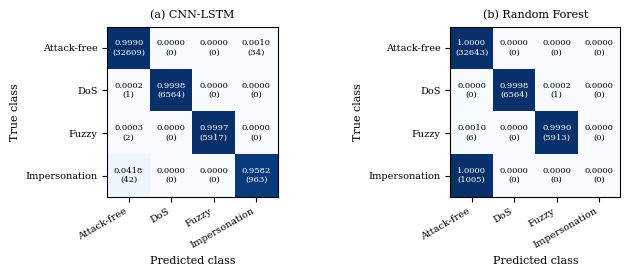

NameError: name 'summary' is not defined

In [ ]:
# ============================================================
# R11. FIGURAS IEEE
# ============================================================
import matplotlib.pyplot as plt
plt.rcParams.update({"font.family": "serif", "font.size": 8, "axes.labelsize": 8,
                     "axes.titlesize": 8, "legend.fontsize": 7, "xtick.labelsize": 7,
                     "ytick.labelsize": 7, "figure.facecolor": "white", "savefig.dpi": 600})

# (a) Matrices de confusión normalizadas: CNN-LSTM vs RF (R5 cronológico, LABEL, semilla 42)
p_rf = PREDICTIONS[(ref_exp, "Random Forest", 42)]
fig, axes = plt.subplots(1, 2, figsize=(7.16, 2.8))
for ax, (title, p) in zip(axes, [("(a) CNN-LSTM", p_ref), ("(b) Random Forest", p_rf)]):
    cm = confusion_matrix(y_ref, p, labels=range(4))
    cmn = cm / cm.sum(1, keepdims=True).clip(min=1)
    ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
    for i in range(4):
        for j in range(4):
            ax.text(j, i, f"{cmn[i, j]:.4f}\n({cm[i, j]})", ha="center", va="center",
                    color="white" if cmn[i, j] > 0.5 else "black", fontsize=6)
    ax.set_xticks(range(4), CLASS_NAMES, rotation=30, ha="right"); ax.set_yticks(range(4), CLASS_NAMES)
    ax.set_xlabel("Predicted class"); ax.set_ylabel("True class"); ax.set_title(title)
fig.tight_layout(); fig.savefig(os.path.join(OUT_DIR, "sando_cm.pdf")); plt.show()

# (b) Macro-F1 por protocolo y etiqueta (media ± DE entre semillas)
s = summary[summary["experiment"].str.startswith("R5_")].copy()
s["setting"] = s["experiment"].str.replace("R5_", "").str.replace("_y_", " / label=")
fig, ax = plt.subplots(figsize=(3.5, 2.4))
settings = list(dict.fromkeys(s["setting"])); x = np.arange(len(settings)); w = 0.38
for k, model in enumerate(["CNN-LSTM V3-C", "Random Forest"]):
    d = s[s["model"] == model].set_index("setting").reindex(settings)
    ax.bar(x + (k - 0.5) * w, d["macro_f1_mean"], w, yerr=d["macro_f1_sd"].fillna(0),
           label=model, capsize=2, color=["#2b6cb0", "#c05621"][k])
ax.set_xticks(x, settings, rotation=20, ha="right")
ax.set_ylabel("Macro-F1 (%)"); ax.set_ylim(max(0, s["macro_f1_mean"].min() - 2), 100.2)
ax.legend(frameon=False, loc="lower left", bbox_to_anchor=(0, 1.02), ncol=2); fig.tight_layout(); fig.savefig(os.path.join(OUT_DIR, "sando_protocols.pdf")); plt.show()
print("✅ Figuras guardadas en", OUT_DIR)

In [ ]:
OUT_DIR = "/content/drive/MyDrive/CAN_IDS_FINAL_EVIDENCE/CARHACKING"
os.makedirs(OUT_DIR, exist_ok=True)
PRED_PKL = os.path.join(OUT_DIR, "revision_predictions.pkl")
CH_SEEDS = SEEDS[:3]
print("Car-Hacking guardará en:", OUT_DIR, "| semillas:", CH_SEEDS)

In [ ]:
OUT_DIR = "/content/drive/MyDrive/CAN_IDS_FINAL_EVIDENCE/REVISION"
PRED_PKL = os.path.join(OUT_DIR, "revision_predictions.pkl")
print("OTIDS guardará en:", OUT_DIR)

In [ ]:
import json, joblib, tempfile
LABEL = "y_win"
Wtr, Wva, Wte = W["train"], W["val"], W["test"]
y = PREDICTIONS[(f"R5_chronological_{LABEL}", "y_true", 0)]
rows = []
for s in SEEDS:
    pe = PREDICTIONS.get((f"R7_ablation_{LABEL}", "embedding(ID) + dt", s))
    ph = PREDICTIONS.get((f"R6_tuned_{LABEL}", "HistGradientBoosting (tuned)", s))
    if pe is None or ph is None:
        continue
    n10, n01, p = mcnemar_exact(y, np.asarray(pe), np.asarray(ph))
    rows.append({"seed": s, "emb ok / HGB wrong": n10, "emb wrong / HGB ok": n01, "p_exact": p})
mc = pd.DataFrame(rows)
mc["p_holm"], mc["significant"] = holm(mc["p_exact"].to_numpy())
print(mc.to_string(index=False))
mc.to_csv(os.path.join(OUT_DIR, "FINAL_mcnemar_emb_vs_hgb.csv"), index=False)

 seed  emb ok / HGB wrong  emb wrong / HGB ok  p_exact   p_holm  significant
   42                  27                  15 0.088430 0.353718        False
    7                  29                  18 0.143865 0.431595        False
  123                  18                  29 0.143865 0.431595        False
 2024                  16                  30 0.054076 0.270380        False
31415                  29                  20 0.252870 0.431595        False


In [ ]:
Xtr, Xva, Xte, _ = prepare(Wtr, Wva, Wte)
Ftr, Fte = flat(Xtr), flat(Xte)
ytr, yva = Wtr[LABEL], Wva[LABEL]
best = {"learning_rate": 0.1, "max_iter": 200, "max_leaf_nodes": 31}   # R6: val macro-F1 = 0.99537
hgb = HistGradientBoostingClassifier(random_state=42, **best).fit(Ftr, ytr)
tmp = tempfile.mkdtemp()
joblib.dump(hgb, f"{tmp}/hgb.joblib")
lat_h = []
for i in range(500):
    t0 = time.perf_counter()
    hgb.predict(Fte[i:i + 1])
    lat_h.append(time.perf_counter() - t0)

vocab = {v: i + 1 for i, v in enumerate(sorted(np.unique(Wtr["ids"])))}
id_lut = np.vectorize(lambda v: vocab.get(v, 0))
I_tr, I_va, I_te = (id_lut(w["ids"]).astype(np.int32) for w in (Wtr, Wva, Wte))
Ntr, Nva, Nte, _ = prepare(Wtr, Wva, Wte, use_dt=True)
Ntr, Nva, Nte = Ntr[..., 1:], Nva[..., 1:], Nte[..., 1:]
m_emb, _, _ = train_keras(lambda: build_emb(WINDOW_SIZE, len(vocab), Ntr.shape[2]),
                          [I_tr, Ntr], ytr, [I_va, Nva], yva, 42)
m_emb.save(f"{tmp}/emb.keras")
f = tf.function(lambda a, b: m_emb([a, b], training=False))
_ = f(I_te[:1], Nte[:1])
lat_e = []
for i in range(500):
    t0 = time.perf_counter()
    _ = f(I_te[i:i + 1], Nte[i:i + 1]).numpy()
    lat_e.append(time.perf_counter() - t0)

size = pd.DataFrame([
    {"model": "CNN-LSTM embedding(ID)+dt", "parameters": m_emb.count_params(),
     "file size (KB)": os.path.getsize(f"{tmp}/emb.keras") / 1024,
     "latency median (ms)": 1e3 * np.median(lat_e), "p99 (ms)": 1e3 * np.percentile(lat_e, 99)},
    {"model": "HistGradientBoosting (tuned)", "parameters": np.nan,
     "file size (KB)": os.path.getsize(f"{tmp}/hgb.joblib") / 1024,
     "latency median (ms)": 1e3 * np.median(lat_h), "p99 (ms)": 1e3 * np.percentile(lat_h, 99)}])
print(size.to_string(index=False, float_format=lambda x: f"{x:,.3f}"))
size.to_csv(os.path.join(OUT_DIR, "FINAL_size_latency_emb_vs_hgb.csv"), index=False)

                       model  parameters  file size (KB)  latency median (ms)  p99 (ms)
   CNN-LSTM embedding(ID)+dt  50,972.000         668.186                1.756     3.503
HistGradientBoosting (tuned)         NaN       2,905.998               12.246    21.561
